# Gaming Behaviour, Addiction and Mental Health Dataset

## Phase 1: Data Understanding

This notebook examines the structure, quality and characteristics of the raw gaming dataset before any cleaning, transformation or modelling is performed.

**Dataset role:** Secondary dataset  
**Prediction target:** `addiction_level`  
**Project type:** Big Data Analytics, Visualization and Machine Learning

In [4]:
from pathlib import Path

import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries imported successfully.")

Libraries imported successfully.


In [5]:
# The notebook is located inside C:\gaming_fyp\notebooks
PROJECT_ROOT = Path.cwd().parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "gaming_mental_health_10M_40features.csv"
)

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Dataset found:", DATA_PATH.exists())

Project root: C:\gaming_fyp
Dataset path: C:\gaming_fyp\data\raw\gaming_mental_health_10M_40features.csv
Dataset found: True


In [6]:
df_raw = pd.read_csv(
    DATA_PATH,
    low_memory=False,
    memory_map=True
)

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [7]:
rows, columns = df_raw.shape

print(f"Number of records : {rows:,}")
print(f"Number of columns : {columns}")

Number of records : 1,000,000
Number of columns : 39


In [8]:
df_raw.head()

,age,gender,income,daily_gaming_hours,weekly_sessions,years_gaming,sleep_hours,caffeine_intake,exercise_hours,stress_level,anxiety_score,depression_score,social_interaction_score,relationship_satisfaction,academic_performance,work_productivity,addiction_level,multiplayer_ratio,toxic_exposure,violent_games_ratio,mobile_gaming_ratio,night_gaming_ratio,weekend_gaming_hours,friends_gaming_count,online_friends,streaming_hours,esports_interest,headset_usage,microtransactions_spending,parental_supervision,loneliness_score,aggression_score,happiness_score,bmi,screen_time_total,eye_strain_score,back_pain_score,competitive_rank,internet_quality
0,51,Female,8615,3.68,22,17,5.26,1.00,0.18,3,4.06,5.02,7.85,9.55,68.80,77.12,2.02,0.39,0.05,0.51,0.23,0.32,1.50,20,186,2.82,1,1,"1,746.97",0,2.87,3.19,5.20,19.69,4.71,5.71,4.81,80,10
1,41,Female,39453,5.70,34,16,9.20,0.70,1.44,8,6.76,7.63,7.06,6.96,38.11,44.94,5.85,0.23,0.37,0.43,0.24,0.32,17.93,37,21,1.34,8,1,342.04,7,4.17,7.73,5.40,26.37,6.62,6.77,3.99,57,2
2,27,Male,40466,1.58,8,22,7.39,2.24,3.15,3,9.57,4.02,1.12,2.61,97.44,54.77,0.08,0.06,0.15,0.48,0.27,0.42,2.99,45,146,3.56,8,1,57.95,9,9.38,2.85,5.17,25.15,9.30,2.16,4.75,59,10
3,55,Male,51076,6.11,39,24,7.99,1.65,2.80,1,4.97,1.40,6.59,6.00,67.65,88.56,2.77,0.53,0.36,0.64,0.57,0.82,1.99,11,133,1.80,6,1,617.32,5,8.24,7.19,8.62,26.42,13.81,4.72,5.37,89,1
4,20,Male,86116,3.65,17,0,7.12,1.02,1.01,2,8.73,4.83,6.03,3.54,62.34,68.82,3.37,0.78,0.25,0.29,0.47,0.83,9.23,24,399,1.30,4,0,"1,398.39",9,6.65,2.53,9.71,25.75,10.74,3.90,6.44,15,10


## 1. Dataset Structure

This section examines the column names, data types and memory usage of the raw dataset.

In [9]:
column_table = pd.DataFrame({
    "No.": range(1, len(df_raw.columns) + 1),
    "Column Name": df_raw.columns
})

column_table

,No.,Column Name
0,1,age
1,2,gender
2,3,income
3,4,daily_gaming_hours
4,5,weekly_sessions
5,6,years_gaming
6,7,sleep_hours
7,8,caffeine_intake
8,9,exercise_hours
9,10,stress_level


In [10]:
numerical_columns = df_raw.select_dtypes(include="number").columns.tolist()
categorical_columns = df_raw.select_dtypes(exclude="number").columns.tolist()

print(f"Numerical columns   : {len(numerical_columns)}")
print(f"Categorical columns : {len(categorical_columns)}")
print()
print("Categorical column names:", categorical_columns)

Numerical columns   : 38
Categorical columns : 1

Categorical column names: ['gender']


In [11]:
data_types = pd.DataFrame({
    "Column": df_raw.columns,
    "Data Type": df_raw.dtypes.astype(str).values
})

data_types

,Column,Data Type
0,age,int64
1,gender,str
2,income,int64
3,daily_gaming_hours,float64
4,weekly_sessions,int64
5,years_gaming,int64
6,sleep_hours,float64
7,caffeine_intake,float64
8,exercise_hours,float64
9,stress_level,int64


In [12]:
df_raw.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 39 columns):
 #   Column                      Non-Null Count    Dtype  
---  ------                      --------------    -----  
 0   age                         1000000 non-null  int64  
 1   gender                      1000000 non-null  str    
 2   income                      1000000 non-null  int64  
 3   daily_gaming_hours          1000000 non-null  float64
 4   weekly_sessions             1000000 non-null  int64  
 5   years_gaming                1000000 non-null  int64  
 6   sleep_hours                 1000000 non-null  float64
 7   caffeine_intake             1000000 non-null  float64
 8   exercise_hours              1000000 non-null  float64
 9   stress_level                1000000 non-null  int64  
 10  anxiety_score               1000000 non-null  float64
 11  depression_score            1000000 non-null  float64
 12  social_interaction_score    1000000 non-null  float64
 13  relations

In [13]:
memory_mb = df_raw.memory_usage(deep=True).sum() / (1024 ** 2)

print(f"DataFrame memory usage: {memory_mb:,.2f} MB")

DataFrame memory usage: 302.31 MB


In [14]:
target_variable = "addiction_level"

print("Prediction target:", target_variable)
print("Target data type:", df_raw[target_variable].dtype)
print("Target minimum:", df_raw[target_variable].min())
print("Target maximum:", df_raw[target_variable].max())

Prediction target: addiction_level
Target data type: float64
Target minimum: 0.0
Target maximum: 10.0


In [15]:
df_raw.info(memory_usage="deep")


<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 39 columns):
 #   Column                      Non-Null Count    Dtype  
---  ------                      --------------    -----  
 0   age                         1000000 non-null  int64  
 1   gender                      1000000 non-null  str    
 2   income                      1000000 non-null  int64  
 3   daily_gaming_hours          1000000 non-null  float64
 4   weekly_sessions             1000000 non-null  int64  
 5   years_gaming                1000000 non-null  int64  
 6   sleep_hours                 1000000 non-null  float64
 7   caffeine_intake             1000000 non-null  float64
 8   exercise_hours              1000000 non-null  float64
 9   stress_level                1000000 non-null  int64  
 10  anxiety_score               1000000 non-null  float64
 11  depression_score            1000000 non-null  float64
 12  social_interaction_score    1000000 non-null  float64
 13  relations

## 2. Initial Data Quality Assessment

This section checks the raw dataset for missing values, duplicate records and the number of unique values in each variable.

In [16]:
missing_summary = pd.DataFrame({
    "Missing Values": df_raw.isnull().sum(),
    "Missing Percentage": (
        df_raw.isnull().mean() * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing Values",
    ascending=False
)

missing_summary

,Missing Values,Missing Percentage
age,0,0.00
gender,0,0.00
income,0,0.00
daily_gaming_hours,0,0.00
weekly_sessions,0,0.00
years_gaming,0,0.00
sleep_hours,0,0.00
caffeine_intake,0,0.00
exercise_hours,0,0.00
stress_level,0,0.00


In [17]:
total_missing = int(df_raw.isnull().sum().sum())
columns_with_missing = int(
    (df_raw.isnull().sum() > 0).sum()
)

print(f"Total missing values       : {total_missing:,}")
print(f"Columns with missing values: {columns_with_missing}")

Total missing values       : 0
Columns with missing values: 0


In [18]:
unique_summary = pd.DataFrame({
    "Column": df_raw.columns,
    "Unique Values": [
        df_raw[column].nunique(dropna=False)
        for column in df_raw.columns
    ]
})

unique_summary

,Column,Unique Values
0,age,47
1,gender,3
2,income,144856
3,daily_gaming_hours,2287
4,weekly_sessions,39
5,years_gaming,25
6,sleep_hours,1236
7,caffeine_intake,1820
8,exercise_hours,1821
9,stress_level,10


In [19]:
gender_summary = (
    df_raw["gender"]
    .value_counts(dropna=False)
    .rename_axis("Gender")
    .reset_index(name="Frequency")
)

gender_summary["Percentage"] = (
    gender_summary["Frequency"]
    / len(df_raw)
    * 100
).round(2)

gender_summary

,Gender,Frequency,Percentage
0,Male,480581,48.06
1,Female,479579,47.96
2,Other,39840,3.98


In [20]:
binary_candidates = [
    column
    for column in df_raw.columns
    if df_raw[column].nunique(dropna=False) == 2
]

print("Binary variable candidates:")
for column in binary_candidates:
    print(
        f"- {column}: "
        f"{sorted(df_raw[column].dropna().unique().tolist())}"
    )

Binary variable candidates:
- headset_usage: [0, 1]


In [22]:
duplicate_count = int(df_raw.duplicated().sum())
duplicate_percentage = (
    duplicate_count / len(df_raw)
) * 100

print(f"Duplicate records    : {duplicate_count:,}")
print(f"Duplicate percentage : {duplicate_percentage:.2f}%")

Duplicate records    : 0
Duplicate percentage : 0.00%


In [23]:
initial_quality_summary = pd.DataFrame({
    "Check": [
        "Total records",
        "Total columns",
        "Total missing values",
        "Columns with missing values",
        "Duplicate records"
    ],
    "Result": [
        f"{len(df_raw):,}",
        len(df_raw.columns),
        f"{total_missing:,}",
        columns_with_missing,
        f"{duplicate_count:,}"
    ]
})

initial_quality_summary

,Check,Result
0,Total records,"1,000,000"
1,Total columns,39
2,Total missing values,0
3,Columns with missing values,0
4,Duplicate records,0


## 3. Descriptive Statistics and Logical Range Validation

Descriptive statistics are used to understand the distribution, central tendency, and range of the main gaming behaviour, addiction, and mental health variables. Logical range validation is also performed to identify potentially unrealistic observations before data cleaning. No records are removed during this stage.

In [24]:
selected_variables = [
    "daily_gaming_hours",
    "weekly_sessions",
    "years_gaming",
    "night_gaming_ratio",
    "weekend_gaming_hours",
    "sleep_hours",
    "exercise_hours",
    "screen_time_total",
    "addiction_level",
    "anxiety_score",
    "depression_score",
    "stress_level",
    "loneliness_score",
    "happiness_score"
]

descriptive_stats = (
    df_raw[selected_variables]
    .describe()
    .T
    .round(2)
)

descriptive_stats

,count,mean,std,min,25%,50%,75%,max
daily_gaming_hours,"1,000,000.00",4.00,2.83,0.00,1.92,3.36,5.38,30.42
weekly_sessions,"1,000,000.00",20.00,11.25,1.00,10.00,20.00,30.00,39.00
years_gaming,"1,000,000.00",12.00,7.21,0.00,6.00,12.00,18.00,24.00
night_gaming_ratio,"1,000,000.00",0.50,0.22,0.00,0.33,0.50,0.67,1.00
weekend_gaming_hours,"1,000,000.00",6.00,4.24,0.01,2.88,5.03,8.07,51.20
sleep_hours,"1,000,000.00",7.00,1.50,-0.17,5.99,7.00,8.01,14.02
exercise_hours,"1,000,000.00",2.00,2.00,0.00,0.58,1.39,2.77,26.48
screen_time_total,"1,000,000.00",8.00,4.00,0.07,5.07,7.35,10.22,46.60
addiction_level,"1,000,000.00",2.82,2.11,0.00,1.25,2.46,3.99,10.00
anxiety_score,"1,000,000.00",5.00,1.98,0.00,3.65,5.00,6.35,10.00


In [25]:
range_checks = {
    "Daily gaming hours above 24":
        df_raw["daily_gaming_hours"] > 24,

    "Weekend gaming hours above 24":
        df_raw["weekend_gaming_hours"] > 24,

    "Sleep hours below 0":
        df_raw["sleep_hours"] < 0,

    "Sleep hours above 24":
        df_raw["sleep_hours"] > 24,

    "Exercise hours below 0":
        df_raw["exercise_hours"] < 0,

    "Exercise hours above 24":
        df_raw["exercise_hours"] > 24,

    "Total screen time below 0":
        df_raw["screen_time_total"] < 0,

    "Total screen time above 24":
        df_raw["screen_time_total"] > 24,

    "BMI below 10":
        df_raw["bmi"] < 10,

    "Night gaming ratio outside 0–1":
        ~df_raw["night_gaming_ratio"].between(0, 1),

    "Multiplayer ratio outside 0–1":
        ~df_raw["multiplayer_ratio"].between(0, 1),

    "Violent games ratio outside 0–1":
        ~df_raw["violent_games_ratio"].between(0, 1),

    "Mobile gaming ratio outside 0–1":
        ~df_raw["mobile_gaming_ratio"].between(0, 1),

    "Addiction level outside 0–10":
        ~df_raw["addiction_level"].between(0, 10)
}

In [26]:
range_validation = pd.DataFrame({
    "Validation Check": range_checks.keys(),
    "Flagged Records": [
        condition.sum() for condition in range_checks.values()
    ]
})

range_validation["Percentage (%)"] = (
    range_validation["Flagged Records"] /
    len(df_raw) * 100
).round(4)

range_validation

,Validation Check,Flagged Records,Percentage (%)
0,Daily gaming hours above 24,54,0.01
1,Weekend gaming hours above 24,2992,0.30
2,Sleep hours below 0,2,0.00
3,Sleep hours above 24,0,0.00
4,Exercise hours below 0,0,0.00
5,Exercise hours above 24,4,0.00
6,Total screen time below 0,0,0.00
7,Total screen time above 24,2321,0.23
8,BMI below 10,211,0.02
9,Night gaming ratio outside 0–1,0,0.00


In [27]:
invalid_row_mask = pd.Series(False, index=df_raw.index)

for condition in range_checks.values():
    invalid_row_mask = invalid_row_mask | condition

invalid_row_count = invalid_row_mask.sum()
invalid_row_percentage = invalid_row_count / len(df_raw) * 100

print(f"Unique rows with at least one range issue: {invalid_row_count:,}")
print(f"Percentage of dataset: {invalid_row_percentage:.4f}%")

Unique rows with at least one range issue: 5,520
Percentage of dataset: 0.5520%


### Initial Interpretation

The descriptive analysis provides an overview of the gaming behaviour, addiction, and mental health indicators contained in the dataset. Most variables fall within their expected measurement ranges. However, several observations contain potentially unrealistic values, including daily gaming duration, weekend gaming duration, total screen time, exercise duration, sleep duration, and BMI.

A total of 5,520 unique records, representing approximately 0.552% of the dataset, were identified as having at least one logical range issue. These observations will be examined and handled during the data preparation stage. The age variable is not evaluated because it has been excluded from the analytical scope of this project.

## 4. Target Variable Analysis

The `addiction_level` variable is selected as the prediction target. It is measured on a numerical scale from 0 to 10. The machine learning model will predict the numerical addiction score, which will subsequently be converted into low, moderate, or high analytical categories for easier interpretation.

These categories are intended for analytical and educational purposes only and do not represent a clinical diagnosis.

In [28]:
target_summary = df_raw["addiction_level"].describe().round(2)

print("Addiction Level Summary")
print("-----------------------")
print(target_summary)
print(f"\nMedian: {df_raw['addiction_level'].median():.2f}")
print(f"Skewness: {df_raw['addiction_level'].skew():.2f}")

Addiction Level Summary
-----------------------
count   1,000,000.00
mean            2.82
std             2.11
min             0.00
25%             1.25
50%             2.46
75%             3.99
max            10.00
Name: addiction_level, dtype: float64

Median: 2.46
Skewness: 0.95


In [29]:
df_raw["addiction_category"] = pd.cut(
    df_raw["addiction_level"],
    bins=[-0.01, 3, 6, 10],
    labels=["Low", "Moderate", "High"],
    include_lowest=True
)

addiction_category_summary = (
    df_raw["addiction_category"]
    .value_counts(sort=False)
    .rename_axis("Addiction Category")
    .reset_index(name="Number of Records")
)

addiction_category_summary["Percentage (%)"] = (
    addiction_category_summary["Number of Records"]
    / len(df_raw) * 100
).round(2)

addiction_category_summary

,Addiction Category,Number of Records,Percentage (%)
0,Low,602208,60.22
1,Moderate,313134,31.31
2,High,84658,8.47


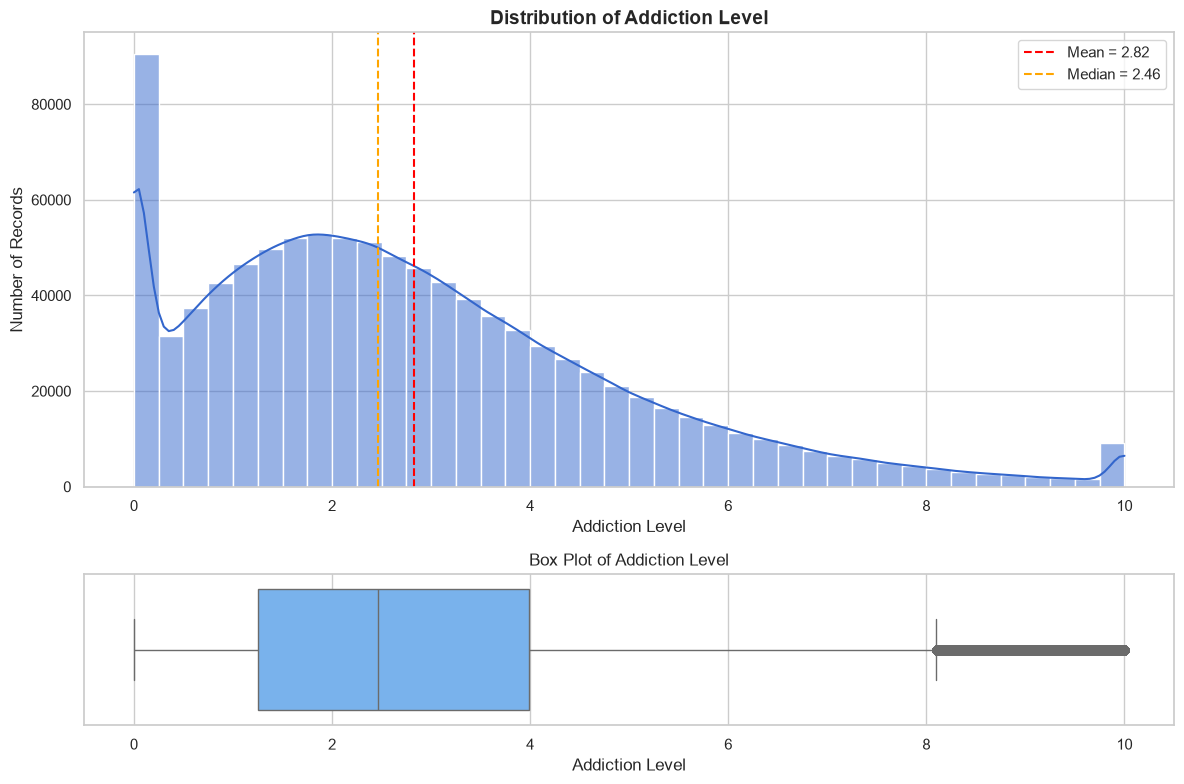

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 8),
    gridspec_kw={"height_ratios": [3, 1]}
)

sns.histplot(
    data=df_raw,
    x="addiction_level",
    bins=40,
    kde=True,
    color="#3366CC",
    ax=axes[0]
)

axes[0].axvline(
    df_raw["addiction_level"].mean(),
    color="red",
    linestyle="--",
    label=f"Mean = {df_raw['addiction_level'].mean():.2f}"
)

axes[0].axvline(
    df_raw["addiction_level"].median(),
    color="orange",
    linestyle="--",
    label=f"Median = {df_raw['addiction_level'].median():.2f}"
)

axes[0].set_title(
    "Distribution of Addiction Level",
    fontsize=14,
    fontweight="bold"
)
axes[0].set_xlabel("Addiction Level")
axes[0].set_ylabel("Number of Records")
axes[0].legend()

sns.boxplot(
    data=df_raw,
    x="addiction_level",
    color="#66B2FF",
    ax=axes[1]
)

axes[1].set_title("Box Plot of Addiction Level")
axes[1].set_xlabel("Addiction Level")

plt.tight_layout()
plt.show()

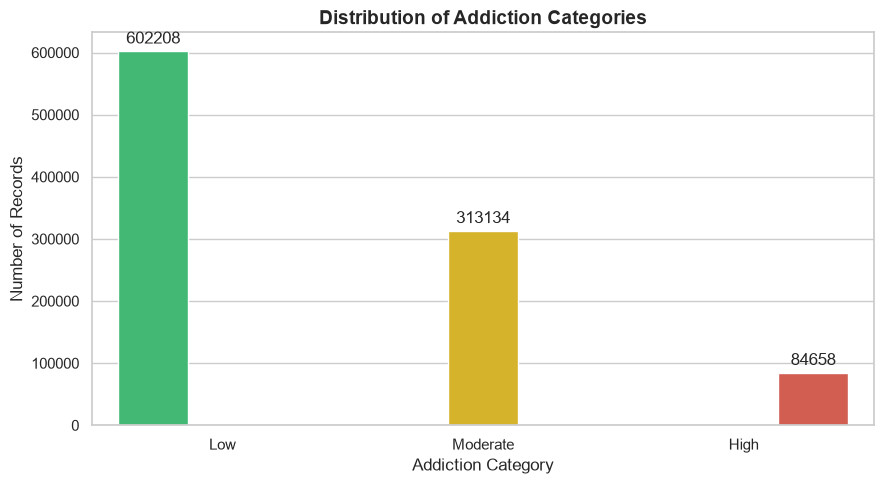

In [32]:
category_order = ["Low", "Moderate", "High"]

plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=df_raw,
    x="addiction_category",
    order=category_order,
    hue="addiction_category",
    palette=["#2ECC71", "#F1C40F", "#E74C3C"],
    legend=False
)

plt.title(
    "Distribution of Addiction Categories",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Addiction Category")
plt.ylabel("Number of Records")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

### Target Variable Interpretation

The addiction level ranges from 0 to 10, confirming that all target values are within the expected scale. The mean addiction score is approximately 2.82, while the median is approximately 2.46. This indicates that the distribution is positively skewed, with most records concentrated within the lower addiction-level range and fewer observations at the higher end.

For user-friendly interpretation, the numerical addiction score is divided into three analytical categories: low, moderate, and high. However, the machine learning model will predict the original numerical addiction score rather than directly predicting the category. The predicted score will then be converted into an appropriate category for display in the Streamlit dashboard.

The predicted outcome should be interpreted as an analytical indication based on patterns in the dataset and not as a medical or clinical diagnosis.

## 5. Correlation Analysis and Initial Feature Selection

Correlation analysis is conducted to examine the relationships between gaming behaviour, lifestyle factors, addiction level, and mental health indicators. This analysis supports the initial selection of variables for predictive modelling.

Mental health indicators are included for descriptive analysis. They are not treated as clinical outcomes or automatically included as predictors of addiction.

In [33]:
gaming_variables = [
    "daily_gaming_hours",
    "weekly_sessions",
    "years_gaming",
    "night_gaming_ratio",
    "weekend_gaming_hours",
    "multiplayer_ratio",
    "toxic_exposure",
    "violent_games_ratio",
    "mobile_gaming_ratio",
    "streaming_hours",
    "microtransactions_spending",
    "screen_time_total"
]

lifestyle_variables = [
    "sleep_hours",
    "exercise_hours"
]

mental_health_variables = [
    "stress_level",
    "anxiety_score",
    "depression_score",
    "loneliness_score",
    "happiness_score"
]

target_variable = ["addiction_level"]

correlation_variables = (
    gaming_variables
    + lifestyle_variables
    + mental_health_variables
    + target_variable
)

print(f"Gaming variables: {len(gaming_variables)}")
print(f"Lifestyle variables: {len(lifestyle_variables)}")
print(f"Mental health indicators: {len(mental_health_variables)}")
print(f"Total variables analysed: {len(correlation_variables)}")

Gaming variables: 12
Lifestyle variables: 2
Mental health indicators: 5
Total variables analysed: 20


In [34]:
correlation_matrix = (
    df_raw[correlation_variables]
    .corr(method="pearson")
    .round(3)
)

correlation_matrix

,daily_gaming_hours,weekly_sessions,years_gaming,night_gaming_ratio,weekend_gaming_hours,multiplayer_ratio,toxic_exposure,violent_games_ratio,mobile_gaming_ratio,streaming_hours,microtransactions_spending,screen_time_total,sleep_hours,exercise_hours,stress_level,anxiety_score,depression_score,loneliness_score,happiness_score,addiction_level
daily_gaming_hours,1.00,0.00,-0.00,0.00,0.00,0.00,-0.00,0.00,-0.00,0.00,0.00,0.71,-0.00,-0.00,-0.00,0.00,-0.00,0.00,0.00,0.89
weekly_sessions,0.00,1.00,-0.00,0.00,0.00,0.00,-0.00,-0.00,-0.00,-0.00,0.00,0.00,0.00,-0.00,-0.00,-0.00,-0.00,0.00,0.00,0.00
years_gaming,-0.00,-0.00,1.00,0.00,0.00,-0.00,-0.00,-0.00,0.00,-0.00,-0.00,-0.00,-0.00,-0.00,0.00,0.00,-0.00,0.00,0.00,0.00
night_gaming_ratio,0.00,0.00,0.00,1.00,-0.00,-0.00,0.00,-0.00,-0.00,0.00,-0.00,0.00,0.00,0.00,0.00,0.00,0.00,-0.00,-0.00,0.00
weekend_gaming_hours,0.00,0.00,0.00,-0.00,1.00,0.00,0.00,0.00,-0.00,-0.00,-0.00,0.00,0.00,0.00,-0.00,-0.00,-0.00,-0.00,0.00,-0.00
multiplayer_ratio,0.00,0.00,-0.00,-0.00,0.00,1.00,0.00,-0.00,-0.00,0.00,0.00,-0.00,0.00,-0.00,0.00,0.00,-0.00,0.00,-0.00,0.00
toxic_exposure,-0.00,-0.00,-0.00,0.00,0.00,0.00,1.00,-0.00,-0.00,-0.00,-0.00,-0.00,0.00,0.00,0.00,-0.00,0.00,0.00,-0.00,-0.00
violent_games_ratio,0.00,-0.00,-0.00,-0.00,0.00,-0.00,-0.00,1.00,0.00,-0.00,-0.00,-0.00,0.00,-0.00,-0.00,0.00,-0.00,-0.00,0.00,0.00
mobile_gaming_ratio,-0.00,-0.00,0.00,-0.00,-0.00,-0.00,-0.00,0.00,1.00,-0.00,-0.00,-0.00,0.00,0.00,0.00,0.00,-0.00,-0.00,-0.00,-0.00
streaming_hours,0.00,-0.00,-0.00,0.00,-0.00,0.00,-0.00,-0.00,-0.00,1.00,0.00,0.00,-0.00,0.00,-0.00,0.00,-0.00,0.00,-0.00,0.00


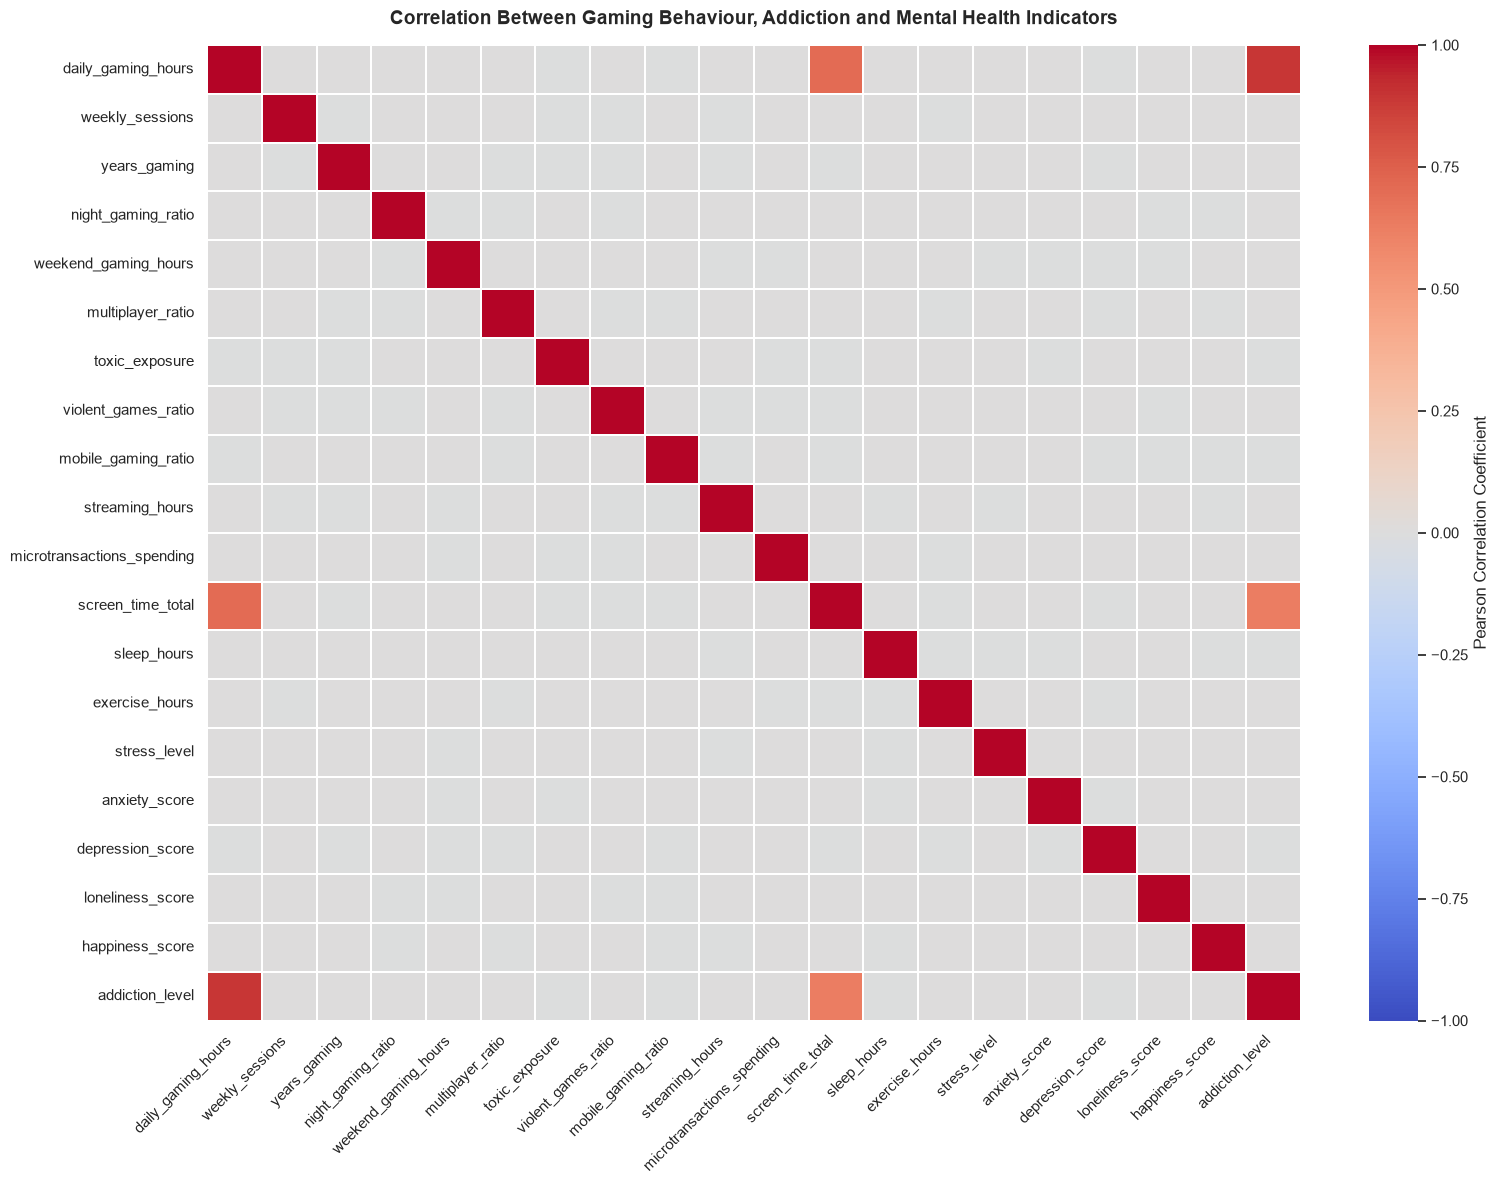

In [35]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=False,
    linewidths=0.3,
    cbar_kws={"label": "Pearson Correlation Coefficient"}
)

plt.title(
    "Correlation Between Gaming Behaviour, Addiction and Mental Health Indicators",
    fontsize=14,
    fontweight="bold",
    pad=15
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [36]:
target_correlations = (
    correlation_matrix["addiction_level"]
    .drop("addiction_level")
    .sort_values(key=abs, ascending=False)
    .reset_index()
)

target_correlations.columns = [
    "Variable",
    "Correlation with Addiction Level"
]

target_correlations

,Variable,Correlation with Addiction Level
0,daily_gaming_hours,0.89
1,screen_time_total,0.63
2,happiness_score,0.00
3,toxic_exposure,-0.00
4,weekly_sessions,0.00
5,years_gaming,0.00
6,multiplayer_ratio,0.00
7,streaming_hours,0.00
8,microtransactions_spending,0.00
9,mobile_gaming_ratio,-0.00


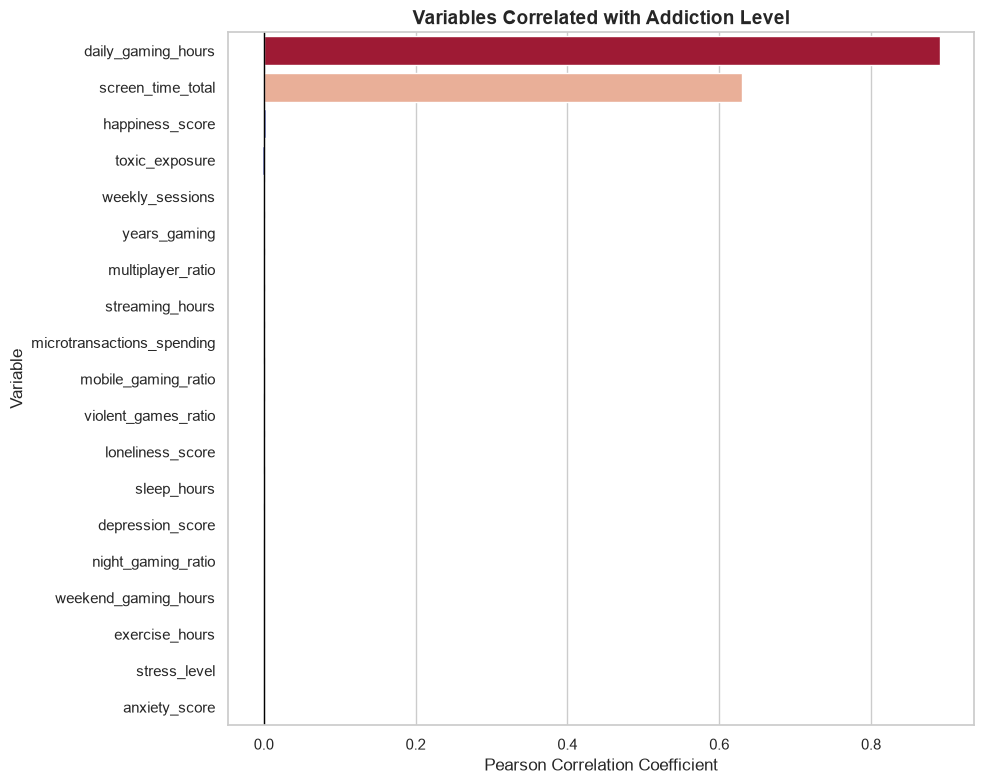

In [37]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=target_correlations,
    x="Correlation with Addiction Level",
    y="Variable",
    hue="Correlation with Addiction Level",
    palette="coolwarm",
    legend=False
)

plt.axvline(0, color="black", linewidth=1)

plt.title(
    "Variables Correlated with Addiction Level",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Pearson Correlation Coefficient")
plt.ylabel("Variable")

plt.tight_layout()
plt.show()


In [38]:
mental_health_relationships = correlation_matrix.loc[
    gaming_variables + ["addiction_level"],
    mental_health_variables
]

mental_health_relationships

,stress_level,anxiety_score,depression_score,loneliness_score,happiness_score
daily_gaming_hours,-0.00,0.00,-0.00,0.00,0.00
weekly_sessions,-0.00,-0.00,-0.00,0.00,0.00
years_gaming,0.00,0.00,-0.00,0.00,0.00
night_gaming_ratio,0.00,0.00,0.00,-0.00,-0.00
weekend_gaming_hours,-0.00,-0.00,-0.00,-0.00,0.00
multiplayer_ratio,0.00,0.00,-0.00,0.00,-0.00
toxic_exposure,0.00,-0.00,0.00,0.00,-0.00
violent_games_ratio,-0.00,0.00,-0.00,-0.00,0.00
mobile_gaming_ratio,0.00,0.00,-0.00,-0.00,-0.00
streaming_hours,-0.00,0.00,-0.00,0.00,-0.00


In [39]:
initial_model_features = [
    "daily_gaming_hours",
    "weekly_sessions",
    "night_gaming_ratio",
    "toxic_exposure",
    "sleep_hours",
    "exercise_hours",
    "screen_time_total"
]

print("Initial modelling features:")
for number, feature in enumerate(initial_model_features, start=1):
    print(f"{number}. {feature}")

print("\nPrediction target: addiction_level")

Initial modelling features:
1. daily_gaming_hours
2. weekly_sessions
3. night_gaming_ratio
4. toxic_exposure
5. sleep_hours
6. exercise_hours
7. screen_time_total

Prediction target: addiction_level


### Correlation Analysis Interpretation

The correlation analysis shows that daily gaming hours have the strongest positive relationship with addiction level. Total screen time also demonstrates a moderately strong positive relationship with the target. This suggests that individuals with longer gaming and overall screen-use durations tend to have higher addiction scores within this dataset.

Most other gaming behaviour, lifestyle, and mental health variables demonstrate weak linear correlations with addiction level. A weak correlation does not necessarily mean that a variable has no value because machine learning models may identify non-linear relationships and interactions that are not captured by Pearson correlation.

The initial predictive variables are daily gaming hours, weekly gaming sessions, night gaming ratio, toxic exposure, sleep hours, exercise hours, and total screen time. Age is excluded according to the defined project scope. Mental health variables will primarily be analysed and visualised as indicators rather than used to produce a medical diagnosis.

Correlation identifies statistical association and does not establish a cause-and-effect relationship.

## 6. Data Preparation and Cleaning

Data preparation is performed to improve the quality and suitability of the dataset for analytics and predictive modelling. The original raw dataset is preserved without modification.

The age variable is retained in the cleaned dataset for descriptive analysis. However, it will not be included as an input variable in the predictive model.

The preparation process includes:

1. Removing duplicate records.
2. Handling missing values in required analytical variables.
3. Removing records with clearly impossible numerical values.
4. Creating an interpretable addiction category.
5. Saving the cleaned dataset in an efficient processed format.

In [40]:
required_columns = [
    "daily_gaming_hours",
    "weekly_sessions",
    "night_gaming_ratio",
    "toxic_exposure",
    "sleep_hours",
    "exercise_hours",
    "screen_time_total",
    "addiction_level"
]

initial_rows = len(df_raw)
initial_columns = df_raw.shape[1]

print(f"Initial number of records: {initial_rows:,}")
print(f"Initial number of columns: {initial_columns}")
print(f"Age column available: {'age' in df_raw.columns}")

Initial number of records: 1,000,000
Initial number of columns: 40
Age column available: True


In [41]:
invalid_conditions = {
    "Daily gaming hours outside 0–24":
        ~df_raw["daily_gaming_hours"].between(0, 24),

    "Weekend gaming hours outside 0–48":
        ~df_raw["weekend_gaming_hours"].between(0, 48),

    "Sleep hours outside 0–24":
        ~df_raw["sleep_hours"].between(0, 24),

    "Exercise hours outside 0–24":
        ~df_raw["exercise_hours"].between(0, 24),

    "Total screen time outside 0–24":
        ~df_raw["screen_time_total"].between(0, 24),

    "BMI outside 10–70":
        ~df_raw["bmi"].between(10, 70),

    "Night gaming ratio outside 0–1":
        ~df_raw["night_gaming_ratio"].between(0, 1),

    "Multiplayer ratio outside 0–1":
        ~df_raw["multiplayer_ratio"].between(0, 1),

    "Violent games ratio outside 0–1":
        ~df_raw["violent_games_ratio"].between(0, 1),

    "Mobile gaming ratio outside 0–1":
        ~df_raw["mobile_gaming_ratio"].between(0, 1),

    "Addiction level outside 0–10":
        ~df_raw["addiction_level"].between(0, 10)
}

cleaning_issue_summary = pd.DataFrame({
    "Cleaning Rule": invalid_conditions.keys(),
    "Affected Records": [
        condition.sum()
        for condition in invalid_conditions.values()
    ]
})

cleaning_issue_summary["Percentage (%)"] = (
    cleaning_issue_summary["Affected Records"]
    / len(df_raw) * 100
).round(4)

cleaning_issue_summary

,Cleaning Rule,Affected Records,Percentage (%)
0,Daily gaming hours outside 0–24,54,0.01
1,Weekend gaming hours outside 0–48,2,0.00
2,Sleep hours outside 0–24,2,0.00
3,Exercise hours outside 0–24,4,0.00
4,Total screen time outside 0–24,2321,0.23
5,BMI outside 10–70,211,0.02
6,Night gaming ratio outside 0–1,0,0.00
7,Multiplayer ratio outside 0–1,0,0.00
8,Violent games ratio outside 0–1,0,0.00
9,Mobile gaming ratio outside 0–1,0,0.00


In [42]:
invalid_cleaning_mask = pd.Series(
    False,
    index=df_raw.index
)

for condition in invalid_conditions.values():
    invalid_cleaning_mask = (
        invalid_cleaning_mask | condition
    )

invalid_record_count = int(invalid_cleaning_mask.sum())
invalid_record_percentage = (
    invalid_record_count / len(df_raw) * 100
)

print(
    f"Unique records with invalid values: "
    f"{invalid_record_count:,}"
)

print(
    f"Percentage of invalid records: "
    f"{invalid_record_percentage:.4f}%"
)

Unique records with invalid values: 2,540
Percentage of invalid records: 0.2540%


In [43]:
df_clean = (
    df_raw.loc[~invalid_cleaning_mask]
    .copy()
)

print(f"Records before cleaning: {len(df_raw):,}")
print(f"Records after range cleaning: {len(df_clean):,}")
print(f"Number of columns retained: {df_clean.shape[1]}")
print(f"Age column retained: {'age' in df_clean.columns}")

Records before cleaning: 1,000,000
Records after range cleaning: 997,460
Number of columns retained: 40
Age column retained: True


In [44]:
rows_before_missing = len(df_clean)

df_clean = (
    df_clean
    .dropna(subset=required_columns)
    .copy()
)

missing_rows_removed = (
    rows_before_missing - len(df_clean)
)

rows_before_duplicates = len(df_clean)

df_clean = (
    df_clean
    .drop_duplicates()
    .copy()
)

duplicate_rows_removed = (
    rows_before_duplicates - len(df_clean)
)

print(
    f"Rows removed due to missing required values: "
    f"{missing_rows_removed:,}"
)

print(
    f"Duplicate rows removed: "
    f"{duplicate_rows_removed:,}"
)

Rows removed due to missing required values: 0
Duplicate rows removed: 0


In [45]:
df_clean["addiction_category"] = pd.cut(
    df_clean["addiction_level"],
    bins=[-0.01, 3, 6, 10],
    labels=["Low", "Moderate", "High"],
    include_lowest=True
)

df_clean[
    [
        "addiction_level",
        "addiction_category"
    ]
].head(10)

,addiction_level,addiction_category
0,2.02,Low
1,5.85,Moderate
2,0.08,Low
3,2.77,Low
4,3.37,Moderate
5,1.34,Low
6,2.33,Low
7,0.67,Low
8,2.51,Low
9,1.64,Low


In [46]:
final_rows = len(df_clean)
final_columns = df_clean.shape[1]

removed_rows = initial_rows - final_rows
retained_percentage = final_rows / initial_rows * 100
removed_percentage = removed_rows / initial_rows * 100

cleaning_summary = pd.DataFrame({
    "Measurement": [
        "Initial records",
        "Records removed",
        "Final cleaned records",
        "Initial columns",
        "Final columns",
        "Records retained (%)",
        "Records removed (%)"
    ],
    "Result": [
        f"{initial_rows:,}",
        f"{removed_rows:,}",
        f"{final_rows:,}",
        f"{initial_columns:,}",
        f"{final_columns:,}",
        f"{retained_percentage:.2f}%",
        f"{removed_percentage:.2f}%"
    ]
})

cleaning_summary

,Measurement,Result
0,Initial records,"1,000,000"
1,Records removed,"2,540"
2,Final cleaned records,"997,460"
3,Initial columns,40
4,Final columns,40
5,Records retained (%),99.75%
6,Records removed (%),0.25%


In [47]:
validation_results = {
    "Missing values in required columns":
        int(
            df_clean[required_columns]
            .isna()
            .sum()
            .sum()
        ),

    "Duplicate records":
        int(df_clean.duplicated().sum()),

    "Invalid daily gaming hours":
        int(
            (
                ~df_clean["daily_gaming_hours"]
                .between(0, 24)
            ).sum()
        ),

    "Invalid weekend gaming hours":
        int(
            (
                ~df_clean["weekend_gaming_hours"]
                .between(0, 48)
            ).sum()
        ),

    "Invalid sleep hours":
        int(
            (
                ~df_clean["sleep_hours"]
                .between(0, 24)
            ).sum()
        ),

    "Invalid exercise hours":
        int(
            (
                ~df_clean["exercise_hours"]
                .between(0, 24)
            ).sum()
        ),

    "Invalid total screen time":
        int(
            (
                ~df_clean["screen_time_total"]
                .between(0, 24)
            ).sum()
        ),

    "Invalid addiction level":
        int(
            (
                ~df_clean["addiction_level"]
                .between(0, 10)
            ).sum()
        )
}

validation_table = pd.DataFrame(
    validation_results.items(),
    columns=[
        "Validation Check",
        "Remaining Issues"
    ]
)

validation_table

,Validation Check,Remaining Issues
0,Missing values in required columns,0
1,Duplicate records,0
2,Invalid daily gaming hours,0
3,Invalid weekend gaming hours,0
4,Invalid sleep hours,0
5,Invalid exercise hours,0
6,Invalid total screen time,0
7,Invalid addiction level,0


In [48]:
model_features = [
    "daily_gaming_hours",
    "weekly_sessions",
    "night_gaming_ratio",
    "toxic_exposure",
    "sleep_hours",
    "exercise_hours",
    "screen_time_total"
]

target_column = "addiction_level"

print(f"Age retained in dataset: {'age' in df_clean.columns}")
print(f"Age included in model: {'age' in model_features}")

print("\nSelected model inputs:")

for number, feature in enumerate(model_features, start=1):
    print(f"{number}. {feature}")

print(f"\nPrediction target: {target_column}")

Age retained in dataset: True
Age included in model: False

Selected model inputs:
1. daily_gaming_hours
2. weekly_sessions
3. night_gaming_ratio
4. toxic_exposure
5. sleep_hours
6. exercise_hours
7. screen_time_total

Prediction target: addiction_level


In [49]:
PROCESSED_DIR = (
    PROJECT_ROOT /
    "data" /
    "processed"
)

PROCESSED_DIR.mkdir(
    parents=True,
    exist_ok=True
)

PROCESSED_PATH = (
    PROCESSED_DIR /
    "gaming_mental_health_cleaned.parquet"
)

df_clean.to_parquet(
    PROCESSED_PATH,
    index=False
)

file_size_mb = (
    PROCESSED_PATH.stat().st_size /
    (1024 ** 2)
)

print("Processed dataset saved successfully.")
print(f"\nFile location:\n{PROCESSED_PATH}")
print(f"\nFile size: {file_size_mb:.2f} MB")
print(f"Saved records: {len(df_clean):,}")
print(f"Saved columns: {df_clean.shape[1]}")

Processed dataset saved successfully.

File location:
C:\gaming_fyp\data\processed\gaming_mental_health_cleaned.parquet

File size: 45.97 MB
Saved records: 997,460
Saved columns: 40


### Data Preparation Outcome

The original raw dataset was preserved, while a separate cleaned dataset was created for analytics, visualisation, and predictive modelling. Records containing clearly impossible numerical values were removed based on predefined logical validation rules.

Weekend gaming duration was allowed to range between 0 and 48 hours because the variable may represent combined gaming time across Saturday and Sunday. Missing values in the required analytical variables and exact duplicate records were also examined.

The age variable was retained in the processed dataset to support descriptive analysis and dashboard visualisation. However, age was excluded from the selected machine-learning inputs. Therefore, dashboard users will not be required to enter their age when generating an addiction-level prediction.

The addiction level remains the numerical prediction target. An additional addiction category was created to convert the predicted score into low, moderate, or high analytical levels for user-friendly interpretation. These categories are educational analytical indicators and do not represent a clinical diagnosis.

The cleaned dataset was validated and saved in Parquet format, which provides efficient storage and faster data loading for large-scale analytics.